Question: Does cointegration found in past data still hold in future data?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.tsa.stattools import coint, adfuller

/Users/saadali/quant-prep/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
tickers = ["XOM", "CVX", "COP", "EOG", "OXY", "MPC", "PSX", "VLO", "SLB", "HAL"]
print(tickers)
print(len(tickers))

['XOM', 'CVX', 'COP', 'EOG', 'OXY', 'MPC', 'PSX', 'VLO', 'SLB', 'HAL']
10


The companies in order are ExxonMobil, Chevron, ConocoPhillips, EOG Resources, Occidental, Marathon Petroleum, Phillips 66, Valero, Schlumberger and Halliburton, hence we can make 10C2 = 45 different pairs.

In [3]:
prices = yf.download(["XOM", "CVX", "COP", "EOG", "OXY", "MPC", "PSX", "VLO", "SLB", "HAL"], start="2015-01-01", end="2025-12-31", auto_adjust=True)["Close"]

[*********************100%***********************]  10 of 10 completed


Downloading the stock's adjusted closing prices in USD at the end of each trading day from the first day of 2015 to the last of 2025.

In [4]:
print(prices.shape)
print(prices.head())
print(prices.isna().sum())

(2765, 10)
Ticker            COP        CVX        EOG        HAL        MPC        OXY  \
Date                                                                           
2015-01-02  47.248627  68.302254  65.388710  31.544537  32.343628  57.110973   
2015-01-05  45.000004  65.572121  61.447224  30.921463  31.443630  54.993652   
2015-01-06  43.142132  65.541779  59.696247  30.617914  31.133045  54.526306   
2015-01-07  43.430069  65.487152  59.320534  31.440687  31.390682  54.533371   
2015-01-08  44.513252  66.985741  61.589016  32.119656  32.128342  55.014893   

Ticker            PSX        SLB        VLO        XOM  
Date                                                    
2015-01-02  47.331120  61.887367  32.348045  56.777916  
2015-01-05  44.469906  60.211426  31.017874  55.224358  
2015-01-06  43.225906  59.033936  30.638748  54.930763  
2015-01-07  43.415783  59.026672  30.400991  55.487358  
2015-01-08  45.105011  59.741840  32.142426  56.410934  
Ticker
COP    0
CVX    0
EOG 

Depicting the closing prices for the first five trading days for each stock, in a table. The 0's show that all data is present, for each stock. (2765, 10) indicates the number of days and stocks respectively that we have stored as data.

In [5]:
train = prices.loc["2015-01-01":"2020-12-31"]
test = prices.loc["2021-01-01": ]
print(train.shape)
print(test.shape)

(1511, 10)
(1254, 10)


Splitting the data into earlier data (train) and later data that will not be touched yet (test).

In [6]:
from itertools import combinations
pairs = list(combinations(prices.columns, 2))
print(len(pairs))
print(pairs[ :5])


45
[('COP', 'CVX'), ('COP', 'EOG'), ('COP', 'HAL'), ('COP', 'MPC'), ('COP', 'OXY')]


Creating the 45 pairs I calculated that there would be earlier, with the first 5 being shown to show the pairs being sorted alphabetically due to 'list'.

In [7]:
results = []
for a, b in pairs:
    p = coint(train[a], train[b])[1]
    results.append({"pair": f"{a}-{b}", "p_value": p})
results = pd.DataFrame(results)

print(results.sort_values("p_value").head(10))


       pair   p_value
3   COP-MPC  0.092771
7   COP-VLO  0.117256
40  PSX-VLO  0.128135
39  PSX-SLB  0.151906
5   COP-PSX  0.162272
15  CVX-VLO  0.180888
33  MPC-VLO  0.182600
13  CVX-PSX  0.202037
19  EOG-OXY  0.206015
31  MPC-PSX  0.242255


Here I tested for cointegration between each pair via 'coint', and printed the 10 pairs with the smallest p-value. Using a significance value of 0.05, I was able to conclude that none of the 45 pairs pass using the training data.
--> One reason for this could be due to the 2020 oil crash included in this timeframe, which would potentially have resulted in weak results due to a sudden break.
--> Another thing to notice would be the COP-MPC pair having the smallest p-value although one is a producer and one a refiner, hence they would have opposite exposure to oil prices. This makes the associated p-value stand out as unusual.

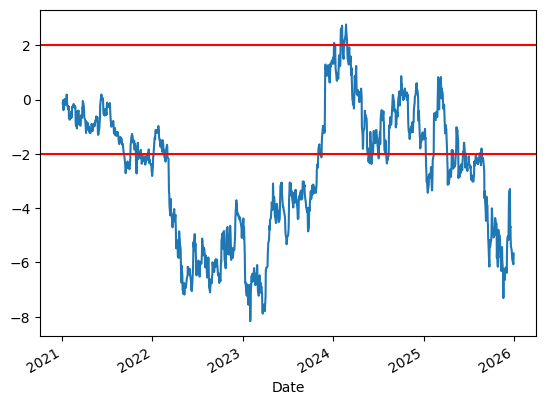

0.2388734071952418


In [8]:
x, y = "VLO", "PSX"
beta, alpha = np.polyfit(train[x], train[y], 1)
spread_train = train[y] - (beta * train[x])
spread_test = test[y] - (beta * test[x])
z_test = (spread_test - spread_train.mean()) / spread_train.std()
z_test.plot()
plt.axhline(2, color = "r"); plt.axhline(-2, color = "r")
plt.show()
print(adfuller(spread_test)[1])

Using the most cointegarted-looking pair from training (PSX, VLO and MPC are all oil refiners, hence the lowest p-value for a combination of 2 of these is our best pair) and a frozen beta from training depicts a spread that stays near 0 at the start of 2021, meaning the relationship held for a short while after training. However, it begins to drift away and is already below -2 in 2022. Although it does come back up and reaches +2.7 in early 2024, it then again collapses and reaches -6 by the end of 2025. This overall suggets that the most promising pair from training failed out of sample. --> One thing to note is that although a z value of -8 is serious, it is partly over-dramatised due to the training spread being calm, hence the standard deviation was small.

In [9]:
p_tests = []
for a, b in pairs:
    beta_ab, alpha_ab = np.polyfit(train[a], train[b], 1)
    sp_test_ab = test[b] - (beta_ab * test[a])
    p_tests.append(adfuller(sp_test_ab)[1])
results["p_test"] = p_tests
print(results.sort_values("p_value").head(10))
print((results["p_test"] < 0.05).sum())

       pair   p_value    p_test
3   COP-MPC  0.092771  0.797969
7   COP-VLO  0.117256  0.678548
40  PSX-VLO  0.128135  0.238805
39  PSX-SLB  0.151906  0.121008
5   COP-PSX  0.162272  0.564285
15  CVX-VLO  0.180888  0.432676
33  MPC-VLO  0.182600  0.539044
13  CVX-PSX  0.202037  0.528005
19  EOG-OXY  0.206015  0.192467
31  MPC-PSX  0.242255  0.360976
1


Here I ran the frozen-beta test on all 45 pairs and compared their training and test p-values. Since none of the values for 'p_test' were below 0.05 out of the top 10 training pairs, none of them passed in the test. This means that even the best looking pairs on training were not able to hold up. However, the '1' at the bottom from the line 'print((results["p_test"] < 0.05).sum())' indicates that there is a pair that passed, but must've ranked badly in training. This suggests that the one pass was within chance, as at the 0.05 level you would expect roughly 2 by luck even if no pair were genuinely cointegrated (45 x 0.05 = 2.25); therefore one pass isn't evidence of anything.

In [10]:
results[results["p_test"] < 0.05]

,pair,p_value,p_test
9,CVX-EOG,0.529219,0.026491


Above I identified the only pair that passed (0.026491 < 0.05), done by creating a True/False column via 'results["p_test"] < 0.05', where putting this inside of results[..] keeps only the rows where it's True, ie boolean filtering.

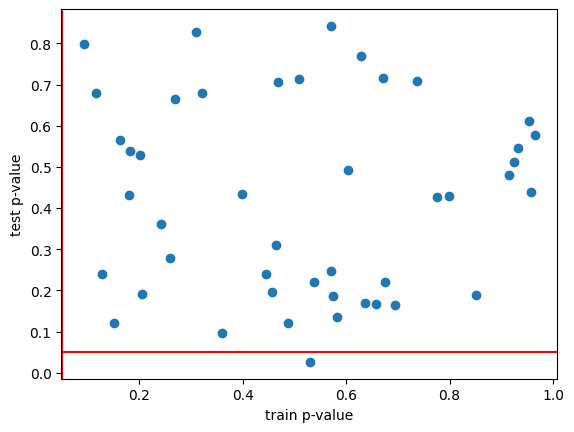

-0.008345892058011948


In [11]:
plt.scatter(results["p_value"], results["p_test"])
plt.axhline(0.05, color = "r"); plt.axvline(0.05, color = "r")
plt.xlabel("train p-value"); plt.ylabel("test p-value")
plt.show()
print(results["p_value"].corr(results["p_test"]))

Plotting the test p-value against the train p-value as a scatter graph depicts a shapeless cloud, where there is no upward trend. This is supported by the correlation value of -0.008346025777760686 being very close to 0, showing that a pair's training p-value tells you nothing about its test p-value: screening on training p-values had no predictive power in this sample. --> The one dot below the horizontal red line represents the one pair that past the test, with its off-centred position emphasising it to be a lucky draw. --> No dot to the left of the vertical line means no pair passed in training, something I established earlier.

In [12]:
state = "flat"
states = []
for z in z_test:
    if state == "flat":
        if z > 2:
            state = "short the spread"
        elif z < -2:
            state = "long the spread"
    elif  state == "short the spread" and z <= 0:
        state = "flat"
    elif state == "long the spread" and z >= 0:
        state = "flat"
    states.append(state)
positions = pd.Series(states, index = z_test.index)


I now introduce the trading rules where our 'state' indicates where we are at in terms of our z-score: 
1- if the state is flat, z above 2 -> Short the spread as y is expensive relative to x, therefore sell y and buy beta units of x. If the gap closes (as it should for a cointegrated pair, ie what we've been testing), y leg gains and x leg may close, but we profit. 
2- if the state is flat, z below -2 -> long the spread as y is cheap relative to x, hence sell beta units of x and buy y. Profit occurs when the spread rises back up. 
3- if the state is short, z does what -> for a cointegrated pair we should have z returning back towards flat (0, or around 0.5 to be safer) as the gap closes. My code returns the state to 'flat' when it reaches or goes beyond 0 to capture proper reversion.
4- if the state is long, z does what -> same as above, consider that cointegration, as we have seen, is rare hence predicted z reversion is not reliable unless established data is known.

In [13]:
print(positions.value_counts())
print((positions != positions.shift(1)).sum())

long the spread     846
flat                358
short the spread     50
Name: count, dtype: int64
10


Above shows us that we were long for approx 2/3 of the time-frame, indicating that the z-score took long periods to get back up towards 0, ie it was reluctant to revert back towards the normal. This makes any trading unreliable as it does not appear to follow a consistent reversion pattern.
The 10 figure shows us that there was 10 changes that occured in the time-frame, although the first row would be compared to 'NaN' and so is automatically true (a starting artifact). This leaves us with 9 real changes, however each trade is an entry plus an exit which means that the last position never closes, since 9 is odd. So we had 4 completed trades and 1 still open at the end. Looking back at the graph, we see that z finished near -6 which means we were still long the spread at the end of 2025, holding a loss that was never realised.

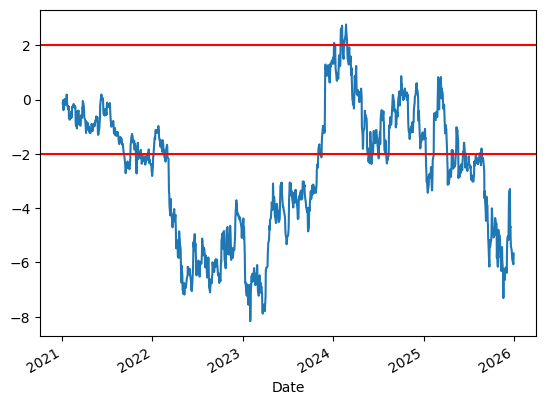

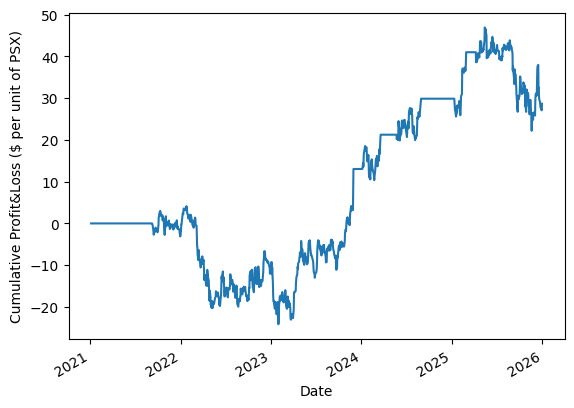

28.66344887358317


In [14]:
z_test.plot()
plt.axhline(2, color = "r"); plt.axhline(-2, color = "r")
plt.show()

pos_num = positions.map({"short the spread": -1, "long the spread": +1, "flat": 0})
day_change = spread_test.diff()
pnl = pos_num.shift(1) * day_change
pnl.cumsum().plot()
plt.ylabel("Cumulative Profit&Loss ($ per unit of PSX)")
plt.show()
print(pnl.sum())



Here I plotted the cumulative trade data from 2021 to 2025 for the VLO, PSX pair and displayed its z-score graph above for reference. We notice that it remains flat until late 2021 (no trades take place) until we lose about 28 during 2022-23 as z fell to -8. It then proceeds to peak near +47 and giving some back to finish at +28.7. This result may seem unusual due to the earlier tests showing this pair to fail, however we will come to notice that the profit is driven by several oridnary trades in a future trade table. We held a long position throughout a long period as the spread fell far below the normal (to -8) and once it recovered, the gain was enough to more than cover the loss. This displays reversion working over about 2 years, however only came to fruition as we sat through a z-score of -8.

WARNING - Do not read too much into this series in particular: it's only one pair and about 4 completed trades with one open one, a tiny sample. In reality, a risk manager wouldn't allow us to hold a position down 20 for a year (too great of a risk). We already concluded that the spread isn't a reliable steady band, and any costs are also missing. --> Normally, this sort of situation would have been stopped out earlier, something we'll now move on to show.

In [15]:
def get_positions(z, stop = None):
    state = "flat"
    wait = None
    states = []
    for v in z:
        if wait == "long" and v >= 0:
            wait = None
        if wait == "short" and v <= 0:
            wait = None
        if state == "flat":
            if wait is None and (stop is None or abs(v) <= stop):
                if v > 2:
                    state = "short the spread"
                elif v < -2:
                    state = "long the spread"
        elif state == "short the spread":
            if v <= 0:
                state = "flat"
            elif stop is not None and v > stop:
                state = "flat"
                wait = "short"
        elif state == "long the spread":
            if v >= 0:
                state = "flat"
            elif stop is not None and v < -stop:
                state = "flat"
                wait = "long"
        states.append(state)
    return pd.Series(states, index = z.index)

Adding stop condition: this reflects the old decision loop as a function with 2 additions. First, a trade is closed if z goes beyond 'stop', and after this a new trade will not open until z crosses back through 0. Second, trades will NOT open if z is already beyond the stop.

In [16]:
def get_pandl(positions, spread):
    num_pos = positions.map({"short the spread": -1, "long the spread": +1, "flat": 0})
    return num_pos.shift(1) * spread.diff()

Above I created a function that takes the positions and the spread and returns to us the daily P&L. I use yesterday's position (via shift(1)) as we can only earn on a position we already held, ie using today's position would be looking ahead. This being a function allows us to reuse the calculation with different stop levels and pairs without copying out the code every time. 

In [17]:
pandl = get_pandl(get_positions(z_test), spread_test)
print(pandl.sum())

28.66344887358317


Re-writing the code above as functions reproduces 28.66, so any difference from here on is due to what I change and not the re-write. I'm now are able to re-run the same functions with a stop level and costs to make the simulation more realistic.

In [18]:
positions = get_positions(z_test)
pandl= get_pandl(positions, spread_test)
held = positions.shift(1)
trade_id = (held != held.shift(1)).cumsum()

rows = []
for tra_id, group in held.groupby(trade_id):
    side = group.iloc[0]
    if side == "flat" or pd.isna(side):
        continue
    rows.append({"side": side,
                "firstday_held": group.index[0],
                "lastday_held": group.index[-1],
                "days": len(group),
                "pandl": pandl.loc[group.index].sum()})
trades = pd.DataFrame(rows)
print(trades)
print(trades["pandl"].sum())
print((train["PSX"] - beta * train["VLO"]).std())

               side firstday_held lastday_held  days      pandl
0   long the spread    2021-09-09   2023-11-30   561  13.044568
1  short the spread    2024-01-08   2024-03-19    50   8.214846
2   long the spread    2024-05-23   2024-08-29    68   8.627895
3   long the spread    2025-01-13   2025-02-27    32  11.134774
4   long the spread    2025-04-08   2025-12-30   184 -12.358634
28.66344887358317
3.935274199572616


Above is a table with each row reflecting a trade with its P&L summed over the days it has been held. The total matches the value of 28.66. We notice that trade 0 is long and slow whereas 1-3 are quick and each earn roughly 2-3 z-units. Also, trade 4 is still open and so the 28.66 includes an unrealised -12.4; considering closed trades only we can say that the total is +41.

In [19]:
for stop in [None, 6, 4, 3]:
    p = get_positions(z_test, stop)
    d = get_pandl(p, spread_test)
    n_entries = ((p != p.shift(1)) & (p != "flat")).sum()
    cum = d.cumsum()
    print(stop, "| pandl:", round(d.sum(), 2), "| entries:", n_entries, "| max drawdown:", round((cum.cummax() - cum).max(), 2))

None | pandl: 28.66 | entries: 5 | max drawdown: 28.28
6 | pandl: -1.72 | entries: 5 | max drawdown: 22.66
4 | pandl: 12.99 | entries: 5 | max drawdown: 15.61
3 | pandl: 6.16 | entries: 5 | max drawdown: 12.32


Above I re-ran the strategy with different stop-losses. No stop resulted in a P&L of 28.66 and a max drawdown of 28.3. Stops of 6, 4 and 3 gave P&Ls of -1.7, 13.0 and 6.2, with drawdowns of 22.7, 15.6 and 12.3 respectively. Therefore we can say that stops reduced the worst drawdown but also cut the return, because the spread eventually did revert and a stopped-out trade missed that recovery. Even relative to the drawdown, no stop necessarily stood out. This suggets that they depend on where each stop happens to 'fire' on this particular path, hence we can say a stop is risk insurance, not a way to add return.

In [20]:
notional = test["PSX"] + (abs(beta) * test["VLO"])
for stop in [None, 4]:
    p = get_positions(z_test, stop)
    d = get_pandl(p, spread_test)
    pos_num = p.map({"short the spread": -1, "long the spread": +1, "flat": 0})
    traded = pos_num.diff().abs().fillna(0)
    for bps in [0, 5, 10]:
        net = d - ((traded * notional * bps) / 10000)
        print(stop, "|", bps, "bps | net pandl:", round(net.sum(), 2))

None | 0 bps | net pandl: 28.66
None | 5 bps | net pandl: 27.72
None | 10 bps | net pandl: 26.78
4 | 0 bps | net pandl: 12.99
4 | 5 bps | net pandl: 11.96
4 | 10 bps | net pandl: 10.94


Above I charged a flat cost of 5 or 10 basis points (0.05-0.10%) of the gross value of both legs everytime a position was opened or closed. This resulted in the no-stop result going from 28.66 to 27.72 and 26.78, and the 4-stop result from 12.99 to 11.96 and 10.94. Costs here are small because there are only 5 trades, so they won't change the conclusion. In reality, costs would be higher as slippage and short-borrowing fees would be taken into account.

In [21]:
def get_trades(p, d):
    held = p.shift(1)
    trade_id = (held != held.shift(1)).cumsum()
    rows = []
    for tra_id, group in held.groupby(trade_id):
        side = group.iloc[0]
        if side == "flat" or pd.isna(side):
            continue
        rows.append({"side": side,
                    "firstday": group.index[0],
                    "lastday": group.index[-1],
                    "days": len(group),
                    "pandl": d.loc[group.index].sum(),
                    "open": bool(group.index[-1] == p.index[-1] and p.iloc[-1] != "flat")})
    return pd.DataFrame(rows)

Above I wrapped the trade table from before into a function so that it can be re-used for different stops. It also adds an "open" flag to mark an unclosed trade by the end of the data, allowing us to separate these incidences from the realised data.

In [22]:
summary = []
for stop in [None, 4]:
    p = get_positions(z_test, stop)
    d = get_pandl(p, spread_test)
    t = get_trades(p, d)
    closed = t[~t["open"]]
    cum = d.cumsum()
    summary.append({"stop": stop if stop else "none",
                    "total": d.sum(),
                    "closed trades": len(closed),
                    "hit rate": (closed["pandl"] > 0).mean(),
                    "pandl closed": closed["pandl"].sum(),
                    "pandl open": t.loc[t["open"], "pandl"].sum(),
                    "max drawdown": (cum.cummax() - cum).max(),
                    "sharpe": d.mean() / d.std() * np.sqrt(252)})
print(pd.DataFrame(summary).round(2))

   stop  total  closed trades  hit rate  pandl closed  pandl open  \
0  none  28.66              4       1.0         41.02      -12.36   
1     4  12.99              5       0.6         12.99        0.00   

   max drawdown  sharpe  
0         28.28    0.35  
1         15.61    0.27  


Results from the stop comparison are repeated above, repeated for no stop and a stop at 4, alongside 2 new measures: hit rate (proportion of closed trades which made money) and Sharpe ratio (average daily P&L divided by its standard deviation, scaled by root(252)). With only a few trades here, the hit rate and Sharpe at the moment are only rough guides.

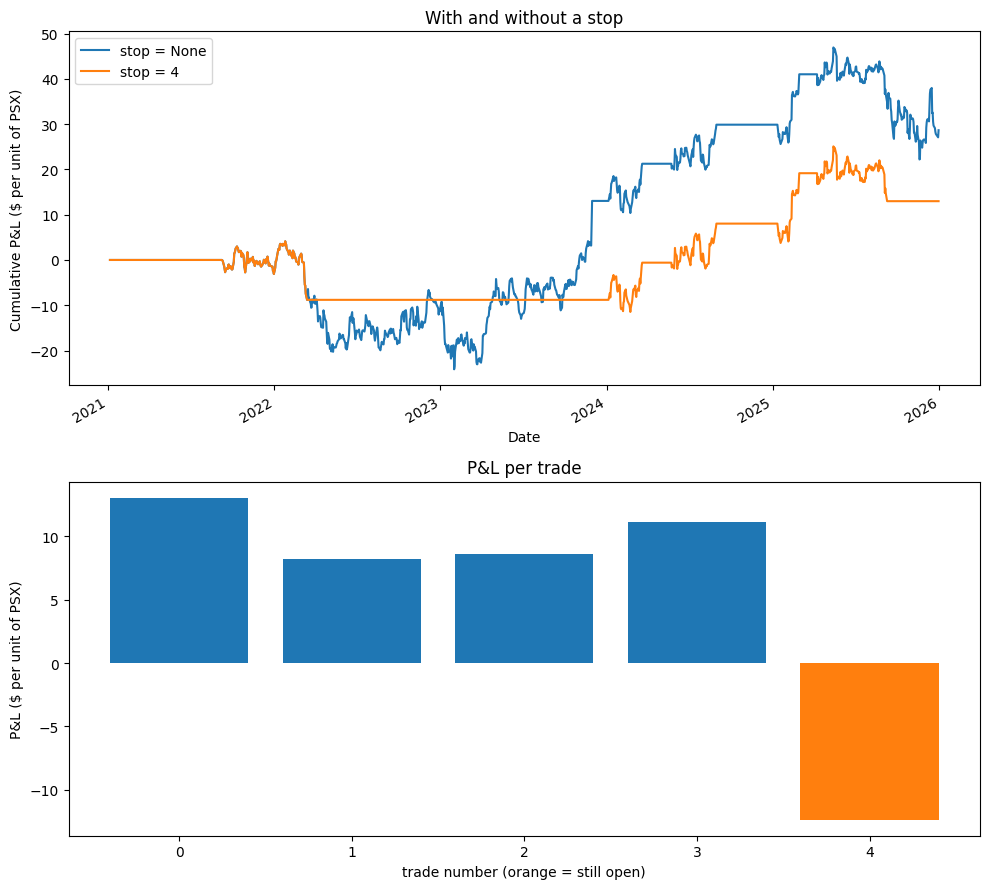

In [23]:
fig, ax = plt.subplots(2, 1, figsize = (10, 9))
for stop in [None, 4]:
    get_pandl(get_positions(z_test, stop), spread_test).cumsum().plot(ax = ax[0], label = f"stop = {stop}")
ax[0].legend(); ax[0].set_ylabel("Cumulative P&L ($ per unit of PSX)"); ax[0].set_title("With and without a stop")
p = get_positions(z_test); d = get_pandl(p, spread_test); t = get_trades(p, d)
ax[1].bar(range(len(t)), t["pandl"], color = ["tab:orange" if o else "tab:blue" for o in t["open"]])
ax[1].set_xlabel("trade number (orange = still open)"); ax[1].set_ylabel("P&L ($ per unit of PSX)"); ax[1].set_title("P&L per trade")
plt.tight_layout()
plt.show()

Top: cumulative P&L with no stop and with a stop at 4. The stop closes the first trade near -8 in approx early 2022, avoiding the slump to about -24 but also missing the late recovery. It also avoids the late 2025 fall from the open trade.

Bottom: P&L per trade; the four closed trades each earned roughly 8 to 13, while the fifth (orange) is still open and is down about 12. Hence a good part of the headline result depends on how that last trade is marked.

       pair  pct no stop  pct stop 4
5   COP-PSX         86.9        54.4
13  CVX-PSX         65.5         3.8
15  CVX-VLO         56.7       -11.8
36  OXY-SLB         41.8        41.8
25  HAL-OXY         37.2        37.2
27  HAL-SLB         33.8        33.8
34  MPC-XOM         27.8        27.8
2   COP-HAL         24.2        24.2
0   COP-CVX         20.2        12.8
7   COP-VLO         17.5       -17.7
pct no stop | positive: 11 of 45 | median: -18.0
pct stop 4 | positive: 15 of 45 | median: -7.8


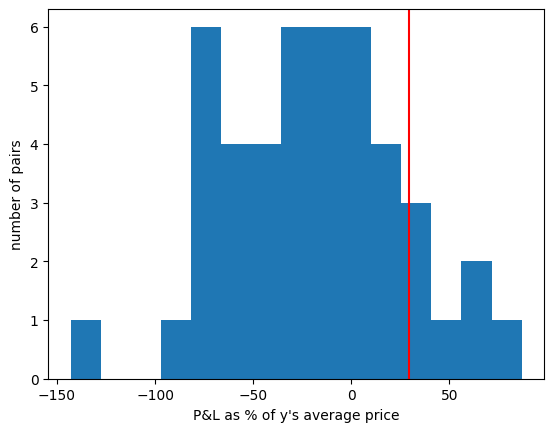

In [24]:
rows = []
for a, b in pairs:
    beta_ab, alpha_ab = np.polyfit(train[a], train[b], 1)
    sp_train = train[b] - (beta_ab * train[a])
    sp_test = test[b] - (beta_ab * test[a])
    z_ab = (sp_test - sp_train.mean()) / sp_train.std()
    row = {"pair": f"{a}-{b}"}
    for stop in [None, 4]:
        d = get_pandl(get_positions(z_ab, stop), sp_test)
        row["pct no stop" if stop is None else "pct stop 4"] = (100 * d.sum()) / test[b].mean()
    rows.append(row)
allpairs = pd.DataFrame(rows)
print(allpairs.sort_values("pct no stop", ascending = False).round(1).head(10))
for col in ["pct no stop", "pct stop 4"]:
    print(col, "| positive:", (allpairs[col] > 0).sum(), "of", len(allpairs), "| median:", round(allpairs[col].median(), 1))
mine = (100 * get_pandl(get_positions(z_test), spread_test).sum()) / test["PSX"].mean()
plt.hist(allpairs["pct no stop"], bins = 15)
plt.axvline(mine, color = "r")
plt.xlabel("P&L as % of y's average price"); plt.ylabel("number of pairs")
plt.show()

Above, I ran the same rule on all 45 pairs, fitting each pair’s beta on the training data, and tried it both with and without a stop at 4. To compare pairs fairly, P&L has been shown as a percentage of the second stock’s average price. It’s just a rough scale, not an actual return on capital.

The results weren’t great. Without a stop, only 11 out of 45 pairs made money, and the median was −18%. Adding the stop helped a bit: 15 out of 45 made money and the median went up to −7.8%.

So PSX-VLO’s +29% was basically a lucky draw from the right tail, not what you’d normally expect. Most pairs that looked cointegrated in training didn’t make money out of sample, which makes sense given they failed the stationarity tests. The stop helps the typical pair, but it actually hurt PSX-VLO, because that pair did end up reverting eventually.

CONCLUSION:

The question: if two stocks look cointegrated in past data, does that relationship actually hold up in the future? To test this, I took 10 US energy stocks (giving 45 pairs), screened them on 2015–2020 data, froze each pair’s hedge ratio, and then tested them on 2021–2025 data the model hadn’t seen.

Statistical result: none of the pairs actually passed the cointegration test in training at the 0.05 level. Out of sample, only 1 of the 45 passed the stationarity test, which is roughly what you’d expect from pure chance (45 × 0.05 ≈ 2.25). There was also basically no link between a pair’s training p-value and its test p-value (correlation of −0.008), so picking pairs based on their training p-values didn’t help predict anything here.

Trading result (PSX–VLO): I used a simple z-score rule, entering when the spread went beyond ±2 and exiting at 0. With no costs, it made +28.66 per unit of PSX. The four closed trades made about +41, but a fifth trade was still open at a loss of about 12.4, and the maximum drawdown was 28.3. Adding a stop at |z| = 4 cut the drawdown to 15.6, but it also cut the P&L to 12.99, because the spread did end up reverting eventually. Trading costs of 5–10 bps only knocked about 1–2 off the result.

All 45 pairs: without a stop, only 11 of the 45 pairs made money, and the median pair lost about 18% of its price level. With the stop, 15 of 45 made money and the median was about −8%. PSX–VLO is in the right tail, so its profit looks more like a lucky draw than proof that the relationship held. Its own test spread still failed the stationarity test (p ≈ 0.24).

Answer: for these stocks, cointegration found in the training period mostly didn’t survive out of sample, and a simple mean-reversion rule lost money on most pairs.

Caveats:

.I only looked at one sector over one test period.
.I picked PSX–VLO after seeing the training results, because it had the third-lowest p-value and both companies are refiners.
.Each pair only had a handful of trades.
.P&L as a percentage of price is just a rough scale, not a return on capital.
.The cost model ignores slippage and borrowing fees.